## Data Science 500 Assignment

This assignment analyses book catalogue data collected from the Books to Scrape website. The goal is to investigate book pricing, ratings, stock availability and genre trends and to develop a linear regression model that estimates book prices from certain book features.

In [1]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

print('Imports imported')

Imports imported


In [2]:
url = 'https://books.toscrape.com/'

response = requests.get(url)

print(response.status_code)

200


In [3]:
soup = BeautifulSoup(response.text, 'html.parser')

print(soup.title.text)


    All products | Books to Scrape - Sandbox



In [4]:
#Find books

books = soup.find_all('article', class_='product_pod')

print(len(books))

20


In [5]:
#Test if required info extracted

book = books[0]

title = book.find('h3').find('a')['title']
price = book.find('p', class_='price_color').text
rating = book.find('p', class_='star-rating')['class'][1]
availability = book.find('p', class_='availability').text.strip()

print(title)
print(price)
print(rating)
print(availability)

A Light in the Attic
Â£51.77
Three
In stock


In [6]:
#Collecting book info

books_data = []

for page in range(1, 21):
    url = f'https://books.toscrape.com/catalogue/page-{page}.html'
    response = requests.get(url)
    soup = BeautifulSoup(response.text, 'html.parser')
    
    books = soup.find_all('article', class_='product_pod')
    
    for book in books:
        title = book.find('h3').find('a')['title']
        price = book.find('p', class_='price_color').text
        rating = book.find('p', class_='star-rating')['class'][1]
        availability = book.find('p', class_='availability').text.strip()
        
        books_data.append({'Title': title,
                           'Price': price,
                           'Rating': rating,
                           'Availability': availability})

print(len(books_data))

400


In [7]:
#Dataframe

df = pd.DataFrame(books_data)

df.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [8]:
df.shape

(400, 4)

In [9]:
from urllib.parse import urljoin
print('imported')

imported


In [10]:
#Get book links

book_links = []

for page in range(1, 21):
    url = f'https://books.toscrape.com/catalogue/page-{page}.html'
    response = requests.get(url)
    soup = BeautifulSoup(response.text, 'html.parser')

    books = soup.find_all('article', class_='product_pod')

    for book in books:
        link = book.find('h3').find('a')['href']
        book_links.append(urljoin(url, link))

print(len(book_links))

400


In [11]:
#Genre and stock

for i, link in enumerate(book_links):
    response = requests.get(link)
    soup = BeautifulSoup(response.text, 'html.parser')

    genre = soup.find('ul', class_='breadcrumb').find_all('li')[2].text.strip()
    stock_text = soup.find('p', class_='instock availability').text.strip()
    quantity = int(stock_text.split('(')[1].split()[0])

    books_data[i]['Genre'] = genre
    books_data[i]['Stock Quantity'] = quantity

print(len(books_data))
print(books_data[0])

400
{'Title': 'A Light in the Attic', 'Price': 'Â£51.77', 'Rating': 'Three', 'Availability': 'In stock', 'Genre': 'Poetry', 'Stock Quantity': 22}


In [12]:
df = pd.DataFrame(books_data)

df.head()

,Title,Price,Rating,Availability,Genre,Stock Quantity
0,A Light in the Attic,Â£51.77,Three,In stock,Poetry,22
1,Tipping the Velvet,Â£53.74,One,In stock,Historical Fiction,20
2,Soumission,Â£50.10,One,In stock,Fiction,20
3,Sharp Objects,Â£47.82,Four,In stock,Mystery,20
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,History,20


In [13]:
df.shape

(400, 6)

# 2. Data Cleaning

This section checks the scraped dataset for missing values, duplicates and inconsistencies. The data will then be cleaned and prepared for analysis and modelling.

In [14]:
#Raw data preserving

df_raw = df.copy()

In [15]:
#Display dataset

df.head()

,Title,Price,Rating,Availability,Genre,Stock Quantity
0,A Light in the Attic,Â£51.77,Three,In stock,Poetry,22
1,Tipping the Velvet,Â£53.74,One,In stock,Historical Fiction,20
2,Soumission,Â£50.10,One,In stock,Fiction,20
3,Sharp Objects,Â£47.82,Four,In stock,Mystery,20
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,History,20


In [16]:
#Check datatypes

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Title           400 non-null    str  
 1   Price           400 non-null    str  
 2   Rating          400 non-null    str  
 3   Availability    400 non-null    str  
 4   Genre           400 non-null    str  
 5   Stock Quantity  400 non-null    int64
dtypes: int64(1), str(5)
memory usage: 18.9 KB


In [17]:
#Sum of missing values

df.isnull().sum()

Title             0
Price             0
Rating            0
Availability      0
Genre             0
Stock Quantity    0
dtype: int64

In [18]:
#Check for duplicate values

print('Duplicate rows:', df.duplicated().sum())
print('Duplicate titles:', df['Title'].duplicated().sum())

Duplicate rows: 0
Duplicate titles: 1


In [19]:
df[df['Title'].duplicated(keep=False)].sort_values('Title')

,Title,Price,Rating,Availability,Genre,Stock Quantity
236,The Star-Touched Queen,Â£46.02,Five,In stock,Fantasy,14
358,The Star-Touched Queen,Â£32.30,Five,In stock,Fantasy,12


In [20]:
#Ratings and avalability counts

print(df['Rating'].value_counts())
print(df['Availability'].value_counts())

Rating
One      88
Two      82
Three    80
Five     77
Four     73
Name: count, dtype: int64
Availability
In stock    400
Name: count, dtype: int64


In [21]:
#Remove spaces

for column in ['Title', 'Rating', 'Availability', 'Genre']:
    df[column] = df[column].str.strip()

In [22]:
#Price conversion (to numbers)

df['Price'] = df['Price'].str.replace(r'[^0-9.]', '', regex=True).astype(float)

df['Price'].head()

0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64

In [23]:
rating_values = {'One': 1,
                 'Two': 2,
                 'Three': 3,
                 'Four': 4,
                 'Five': 5}

df['Rating Score'] = df['Rating'].map(rating_values)

df[['Rating', 'Rating Score']].head()

,Rating,Rating Score
0,Three,3
1,One,1
2,One,1
3,Four,4
4,Five,5


In [24]:
print(df['Rating Score'].value_counts().sort_index())
print('Missing rating scores:', df['Rating Score'].isnull().sum())

Rating Score
1    88
2    82
3    80
4    73
5    77
Name: count, dtype: int64
Missing rating scores: 0


In [25]:
df.info()

print(df.isnull().sum())
print('Dataset shape:', df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Title           400 non-null    str    
 1   Price           400 non-null    float64
 2   Rating          400 non-null    str    
 3   Availability    400 non-null    str    
 4   Genre           400 non-null    str    
 5   Stock Quantity  400 non-null    int64  
 6   Rating Score    400 non-null    int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 22.0 KB
Title             0
Price             0
Rating            0
Availability      0
Genre             0
Stock Quantity    0
Rating Score      0
dtype: int64
Dataset shape: (400, 7)


In [26]:
df.to_csv('books.csv', index=False)

# 3. Data Visualisation

This section displays the distribution of book prices, star ratings and average prices across genres. It also investigates the relationship between book ratings and prices to identify patterns within the dataset.

In [27]:
import matplotlib.pyplot as plt

print('imported')

imported


In [28]:
df['Price'].describe()

count    400.00000
mean      34.95980
std       14.52635
min       10.16000
25%       21.93000
50%       36.80500
75%       47.68250
max       59.90000
Name: Price, dtype: float64

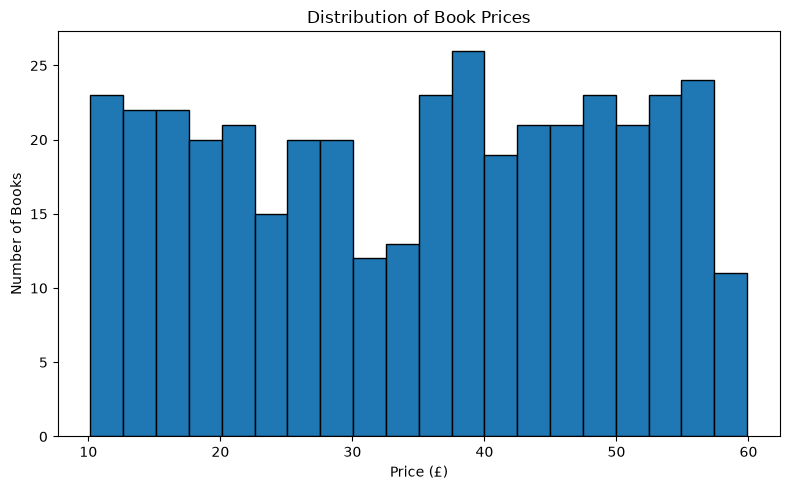

In [29]:
#Book price comparison

plt.figure(figsize=(8, 5))
plt.hist(df['Price'], bins=20, edgecolor='black')
plt.title('Distribution of Book Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Books')
plt.tight_layout()
plt.show()

### Interpretation:

The histogram shows that book prices are spread in a range from £10 to £60. The distribution is fairly spread out, with many price intervals containing around 15–25 books. There is a drop in the graph at around the £30–£35, while the peak frequency appears around £37.5–£40. The final price interval near £60 contains fewer books than most of the other intervals. The data confirms that there isn't a single dominant price point.

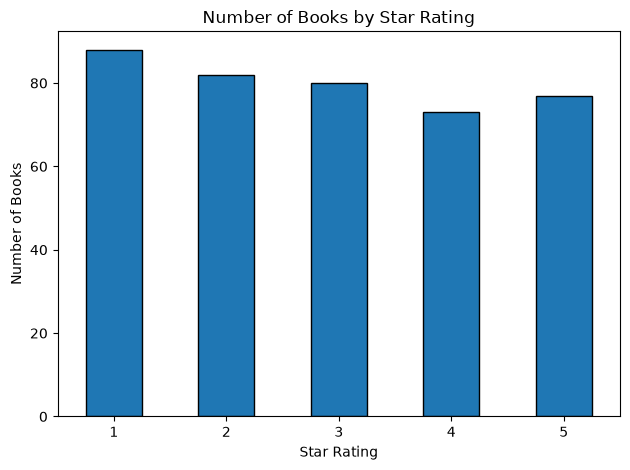

In [30]:
#Star ratings

df['Rating Score'].value_counts().sort_index().plot(kind='bar', edgecolor='black')

plt.title('Number of Books by Star Rating')
plt.xlabel('Star Rating')
plt.ylabel('Number of Books')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation:

The bar chart shows that all five star ratings are represented in the dataset. One star books are the most frequent, with around 88 books, while four star books are the least frequent, with about 72. The number of books decreases from one star to four star ratings before increasing slightly for five star books. The differences between the rating groups are small, which suggests that the dataset contains a broad distribution of ratings rather than a high concentration in a single rating.

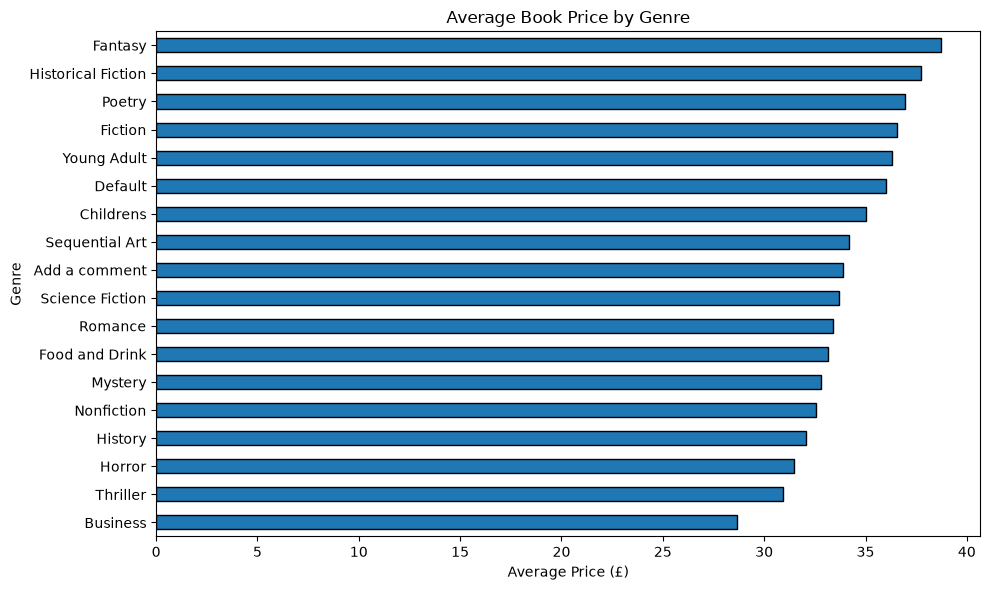

In [31]:
#Average price by range

genre_counts = df['Genre'].value_counts()
common_genres = genre_counts[genre_counts >= 5].index

genre_prices = df[df['Genre'].isin(common_genres)].groupby('Genre')['Price'].mean().sort_values()

genre_prices.plot(kind='barh', figsize=(10, 6), edgecolor='black')

plt.title('Average Book Price by Genre')
plt.xlabel('Average Price (£)')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

### Interpretation:

The horizontal bar chart shows that average book prices differ across genres, however the differences are small. Fantasy has the highest average price at around £40, which is followed by Historical Fiction at around £39. Business has the lowest average price at about £29. Most of the genres have average prices between £32 and £38. This suggests that genre may be associated with book prices in the dataset. However the results only represent the 400 books that were sampled and not the whole catalogue.

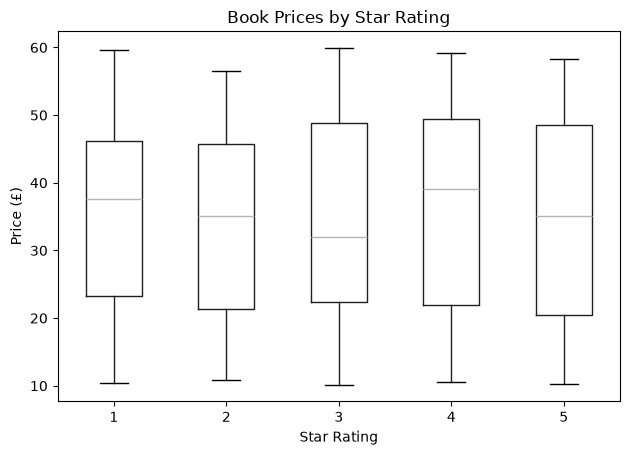

In [32]:
#Rating vs price (box plot for measure of spread of the data)

df.boxplot(column='Price', by='Rating Score', grid=False)

plt.suptitle('')
plt.title('Book Prices by Star Rating')
plt.xlabel('Star Rating')
plt.ylabel('Price (£)')
plt.tight_layout()
plt.show()

### Interepretation

The box plot shows that across all five star ratings, book prices display a similar spread of around £10 to £60 per group. Median prices are consistent across the ratings, suggesting that higher ratings do not correspond to higher prices. The significant overlap in interquartile ranges (IQR) shows that books with different ratings often cost about the same. However, star ratings are not a strong indicator of price and don't imply a strong relationship between the ratings and the prices.

# 4. Predictive Modelling

This section involved developing a linear regression model to estimate book prices using star ratings, stock quantities and genres. The model will be trained on part of the dataset and evaluated on unseen data to assess its predictive performance.

In [33]:
#Libraries for modelling

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print('Imports successful')

Imports successful


In [34]:
#initialising

X = df[['Rating Score', 'Stock Quantity']].copy()
y = df['Price']

genre_dummies = pd.get_dummies(df['Genre'], prefix='Genre', dtype=int)
genre_dummies = genre_dummies.drop(columns=['Genre_Fiction'])

X = pd.concat([X, genre_dummies], axis=1)

print('Features:', X.shape)
print('Target:', y.shape)

Features: (400, 42)
Target: (400,)


### Feature selection

Rating Score, Stock Quantity and Genre were selected as features because they may be associated with book prices. Rating Score represents the book's star rating, Stock Quantity indicates the number of copies available and Genre allows prices to be compared across different categories. These features were selected to investigate whether book ratings, stock and category differences could help explain differences in book prices. Genre was converted into numeric variables so it could be used by the linear regression model, with Fiction serving as the reference category.

In [35]:
#training and testing vars

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training records:', len(X_train))
print('Testing records:', len(X_test))

Training records: 320
Testing records: 80


In [36]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](42,)","[-0.12,-0.74, 1.42,...,14.32, 0.12, 1.72]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](42,)","['Rating Score','Stock Quantity','Genre_Add a comment',...,'Genre_Travel', 'Genre_Womens Fiction','Genre_Young Adult']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,45.84
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,42
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(41)


In [37]:
#predict book prices

y_pred = model.predict(X_test)

results = pd.DataFrame({'Actual Price': y_test, 'Predicted Price': y_pred})

results.head()

,Actual Price,Predicted Price
209,15.48,36.413086
280,41.56,35.421778
33,36.89,31.060408
210,46.82,36.174010
93,46.91,35.618986


In [38]:
#Model evaluation to test model performance

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('Mean Absolute Error:', round(mae, 2))
print('Mean Squared Error:', round(mse, 2))
print('Root Mean Squared Error:', round(rmse, 2))
print('R-squared:', round(r2, 3))

Mean Absolute Error: 12.81
Mean Squared Error: 221.84
Root Mean Squared Error: 14.89
R-squared: -0.119


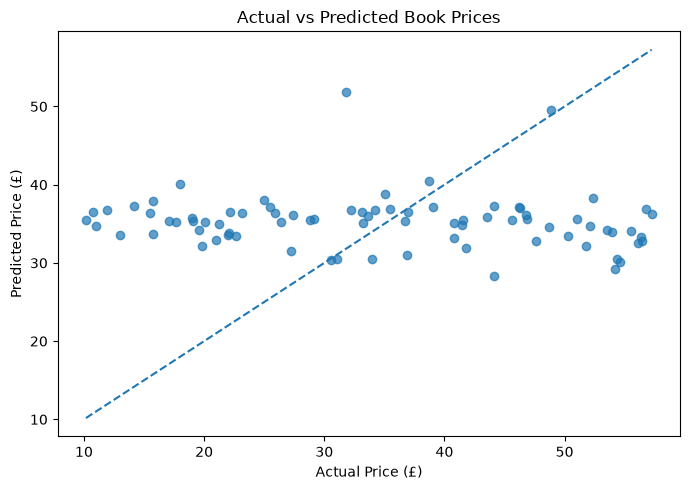

In [39]:
#Actual vs predicted prices

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         linestyle='--')

plt.title('Actual vs Predicted Book Prices')
plt.xlabel('Actual Price (£)')
plt.ylabel('Predicted Price (£)')
plt.tight_layout()
plt.show()

In [40]:
coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})

coefficients.sort_values('Coefficient', ascending=False)

,Feature,Coefficient
29,Genre_Politics,1.908668e+01
10,Genre_Contemporary,1.784637e+01
17,Genre_Health,1.705327e+01
8,Genre_Christian,1.647281e+01
39,Genre_Travel,1.432452e+01
35,Genre_Self Help,1.381557e+01
25,Genre_New Adult,1.374875e+01
3,Genre_Art,1.296355e+01
33,Genre_Science,1.089744e+01
23,Genre_Music,4.725773e+00


### Interpretation of Model Coefficients

Fiction was used as the reference genre when comparing the coefficients. The results show that Politics, Contemporary and Health had some of the highest positive coefficients, meaning that the model predicted higher prices for these genres compared to Fiction. However, Autobiography and Biography had lower predicted prices than Fiction when the other features were kept constant.

The Rating Score had a coefficient of around -0.12, which suggests a small negative relationship between ratings and prices in the model. Stock Quantity had a coefficient of around -0.74, which means that higher stock quantities were associated with lower predicted prices.

These results show how the different features relate to book prices according to the model. However, they do not mean that these features directly cause prices to increase or decrease. The results should also be interpreted cautiously, because the model did not perform well when predicting prices for the test data.

### Limitations of the predictive model

The model achieved an R-squared value of -0.119, which means that it performed worse than simply predicting the average book price. The Mean Absolute Error was £12.81 which shows that the predicted prices were often quite far from the actual prices.

The model was trained using 400 books and only considered their ratings, stock quantities and genres. These features may not be enough to explain the differences in book prices. The dataset also contains a genre category called 'Add a comment', which is unusual, which may also affect the results for that category.

This shows that the model is not reliable enough for accurate price predictions in its current form. It could be improved by checking the data more carefully, using a larger dataset and including other relevant features. Other predictive models could also be tested to see whether they produce better results.

# 5. Conclusion

This assignment involved collecting and analysing book data from the Books to Scrape website. 400 books were collected, including information about their prices, ratings, availability, stock quantities and genres. The dataset was checked for missing values, duplicate records and inconsistent data types before being prepared for analysis.

The visualisations showed that book prices were spread across a range of £10 to £60, while all five star ratings were represented in the dataset. Average prices differed across genres, with Fantasy having one of the highest average prices and Business having the lowest among the genres included in the comparison. However, the box plot showed that prices were fairly similar across the different star ratings, which suggests that ratings was not a strong indicator of pricing.

A linear regression model was also developed to estimate book prices using ratings, stock quantities and genres. However, the model achieved an R-squared value of -0.119 and a Mean Absolute Error of £12.81. This indicates that the model did not predict prices reliably and performed worse than simply predicting the average price.

The results show that collecting and analysing data can help identify patterns, but the quality of the predictions depends on how useful the selected features of that data are. The model could be improved by using a larger dataset, checking unusual category labels and testing other predictive models.

In [41]:
df.to_csv('books.csv', index=False)

In [42]:
#Verify csv

cleaned_df = pd.read_csv('books.csv')

print('Dataset shape:', cleaned_df.shape)
print('Missing values:', cleaned_df.isnull().sum().sum())
cleaned_df.head()

Dataset shape: (400, 7)
Missing values: 0


,Title,Price,Rating,Availability,Genre,Stock Quantity,Rating Score
0,A Light in the Attic,51.77,Three,In stock,Poetry,22,3
1,Tipping the Velvet,53.74,One,In stock,Historical Fiction,20,1
2,Soumission,50.10,One,In stock,Fiction,20,1
3,Sharp Objects,47.82,Four,In stock,Mystery,20,4
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,History,20,5
